# AAI-540 Group-3 Project: AWS CloudTrail Suspicious Activity Classifier


This project develops a machine learning workflow to identify potentially suspicious AWS activity from CloudTrail logs.
CloudTrail data → Amazon S3 → Notebook-side preparation → XGBoost training → Model evaluation → Endpoint deployment and monitoring

1. **CloudTrail data:** Historical logs provide records of AWS API activity, including event times, operations, identities, and request outcomes.

2. **Amazon S3:** The source archive is stored in S3. Prepared datasets, model artifacts, and evaluation reports are stored separately to support traceability and reproducibility.

3. **Data preparation:** Download the log files, validates records, removes duplicates, handles missing fields, and creates model features. Security rules generate weak labels, and events are divided chronologically into training, validation, and test datasets.

4. **XGBoost training:** An XGBoost classifier is trained inside the notebook kernel to predict the rule-generated suspicious-activity labels. Training therefore uses the notebook’s compute and memory.

5. **Model evaluation:** Validation and test results measure precision, recall, F1, ROC AUC, and average precision. These metrics assess agreement with weak labels rather than independently verified attacks. A validation quality gate determines whether the model can proceed to deployment review.

6. **Endpoint deployment:** After approval, the trained model can be deployed to a SageMaker real-time endpoint using separate managed hosting compute.

7. **Monitoring:**  Monitoring checks data quality and drift, while operational monitoring tracks endpoint health and failures. Deployment and monitoring require the appropriate AWS permissions and configuration.

### Problem statement
Cloud platforms generate a large volume of API activity logs, and security teams cannot manually inspect every CloudTrail event in real time. Important signals such as root-user activity, IAM policy changes, access key creation, S3 bucket enumeration, CloudTrail tampering, unusual source IPs, and repeated authorization failures can be buried inside normal operational activity.

This project builds an end-to-end MLOps workflow that uses AWS CloudTrail data to classify events as normal or suspicious. One XGBoost model is fitted in the SageMaker notebook kernel and can be deployed from S3 to a SageMaker real-time endpoint to return a risk score for analyst review.

### Model objective:
Supervised binary classification

| Value | Class | Operational interpretation |
|---|---|---|
| 0 | normal | Does not match the implemented high-risk labeling policy; not a guarantee of safety. |
| 1 | suspicious | Matches risk patterns involving IAM, S3, STS, EC2, KMS, CloudTrail, root activity, or authorization failures. |

XGBoost uses `binary:logistic` and produces a score between 0 and 1. The default classification threshold is **0.50**. A separate **0.80** threshold routes high scores to alerts. These are initial policy choices, not empirically proven operating points. Probability calibration is assessed with Brier score and log loss; the score must not be represented as a calibrated probability of a real attack.

**Scope:** The model scores individual events for review.

### Enhancements:
- **Unfamiliar IPs**, **rare APIs**, and **authorization failures** are warning signals, not proof of an attack.
- Tracking repeated failures across sessions is a future enhancement.
- The endpoint returns a score when called; CloudTrail delivery adds a separate delay.
- Can be integrated with AWS Bedrok for AI assistant chatbot usecases.

### System Design:

![System Design](resources/ArchiectureDiagram.jpeg)



## 2. Prepare Data and Feature Engineering

### 2.1 Dataset 
The dataset contains 1,939,207 events from 2017-02-12 through 2020-10-07, 9,402 anonymized source IPs, 8,811 user agents, and 1,242 attempted APIs. IPs and account identifiers were anonymized; object-level S3/Lambda data events were not enabled. Therefore, IP geolocation, reputation lookups, attack attribution, and conclusions about object access are invalid for this dataset.

This dataset is selected because it contains real structured API activity relevant to the proposed security task. Its filename suggests the FL AWS training environment, but the archive alone does not establish licensing, collection methodology, representativeness, or verified attack labels. Record the original download URL, license, and provenance before sharing the dataset or making production claims.

### 2.2. Labeling approach: weak supervision

Security rules create versioned labels, and XGBoost learns to predict them. High test scores show agreement with these rules, **not proven attack detection**. Because the rules and model use similar event features, strong scores are expected—even after label and reason columns are removed.

| Rule | Weak label |
|---|---|
| Root identity | Suspicious |
| Selected CloudTrail configuration changes or logging stops | Suspicious |
| Selected IAM credential/policy changes, S3 access changes, KMS key/grant changes | Suspicious; authorized administration can also match |
| Selected S3/STS/EC2 APIs with explicitly false MFA or authorization failure | Suspicious |
| Authorization failure | Suspicious; includes benign mistakes |
| None of the above | Normal under this policy |


### 2.3 Feature selection 
| Feature group | Selected fields |
|:---|:---|
| **Categorical** | `event_source`, `event_name`, `region`, `identity_type`, `mfa`, `error_code`, `ip_kind`, `agent_family` |
| **Time** | Cyclic hour (`hour_sin`, `hour_cos`) and weekday |
| **Activity indicators** | Error flag, authorization-failure flag, and read-only indicator |
| **Training-reference features** | Event frequency and unseen-IP indicator |
| **Excluded** | Account IDs, principal IDs/ARNs, raw IPs, event IDs, session IDs, raw user agents, error messages, request parameters, response bodies, target labels, and weak-label reasons |

### 2.4 Data Handling
- **Event IDs:** Identify and remove duplicate events.
- **User identities:** Replace identifiers with hashes to check whether the same identities appear across datasets.
- **IP addresses:** Group addresses by type and use hashes to identify IPs not seen during training. Hashing does not make them fully anonymous.
- **Event times:** Extract the hour and weekday. Use the original time to split events in order, with gaps between datasets.
- **Preventing data leakage:** Learn categories, event frequencies, and known IPs from training data only.

### 2.5 Feature engineering

- **Categories:** Event source/name, region, identity type, MFA status (enabled, disabled, or unknown), error code, IP type, and user-agent family.
- **Numbers:** Hour represented cyclically, weekday, error flags, read-only status, event frequency, and whether an IP appeared in training.
- **Training-only references:** Learn the top 64 categories per field, event frequencies, and known IPs from training data only. Other categories become “unknown.” XGBoost does not require numerical scaling.
- **Excluded information:** Raw request/response data, credentials, user/account identifiers, event IDs, original timestamps, labels, and labeling reasons.
- **Hashed identifiers:** IP hashes check whether an address appeared in training. Principal hashes support checks for identity overlap between datasets. Hashing does not guarantee anonymity.
- **Unseen-IP limitation:** Every training IP is already “known,” so this feature is always zero during training and may provide no predictive value. It does not establish novelty-detection capability.

## 3. AWS Cloud Environment Setup

- Open JupyterLab in AWS SageMaker.
- Use Python 3.10–3.12 with access to download required packages.
- Run the bootstrap cell once and select the `Python (CloudTrail SageMaker SDK v2)` kernel.
- Run the remaining cells from the configuration step onward.
- Upload `flaws_cloudtrail_logs.tar` to the notebook’s folder. [Download archive](https://summitroute.com/downloads/flaws_cloudtrail_logs.tar)
- If the archive is already in S3, specify its location in `EXISTING_RAW_S3_URI`.
- Ensure the notebook has enough disk space and memory for preparation and training.
- Begin with `SAMPLE_FRACTION = 0.1` (10% of events), then use `1.0` for the full dataset.
- you must have execution role has the necessary permissions for S3 access, endpoint deployment, and monitoring.

In [2]:
ENV_SETUP = False   ## False if packages are alredy installed. 
if ENV_SETUP:
    from pathlib import Path
    import os
    import subprocess
    import sys
    import venv
    
    # Create virutal environment
    env_dir = Path.home() / ".venvs" / "cloudtrail-sagemaker-v2"
    python_in_env = env_dir / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    if not python_in_env.exists():
        venv.EnvBuilder(with_pip=True).create(env_dir)
    
    subprocess.check_call([str(python_in_env), "-m", "pip", "install", "--upgrade", "pip"])
    subprocess.check_call([
        #str(python_in_env), "-m", "pip", "install", "jinja2==3.1.6"
        "sagemaker==2.257.5", "numpy==1.26.4", "pandas==2.3.3",
        "matplotlib==3.9.2", "ijson==3.3.0", "xgboost==1.7.6",
        "scikit-learn==1.5.2", "ipykernel", "jinja2==3.1.6"
    ])
    subprocess.check_call([
        str(python_in_env), "-m", "ipykernel", "install", "--user",
        "--name", "cloudtrail-sagemaker-v2",
        "--display-name", "Python (CloudTrail SageMaker SDK v2)",
    ])
    print("Created the isolated kernel: Python (CloudTrail SageMaker SDK v2)")
    print("Select it from the Kernel menu, then run the notebook from the configuration step.")

### 3.1. Set project options
- **RUN_PROJECT** = True            # True prepares data, uploads S3 inputs, and fits XGBoost in this notebook kernel. 
- **DEPLOY_ENDPOINT** = True        # True deploys a billable real-time endpoint after model approval.
- **APPROVE_MODEL** = True          # Review validation/test reports before changing this.
- **ENABLE_MONITORING** = False     # True creates CloudWatch alarms and a data-quality schedule.
- **CLEAN_UP** = True               # True deletes run-specific live resources at the final step.
- **KMS_KEY_ID** = None             # Optional customer-managed KMS key ARN.
- **SNS_TOPIC_ARN** = ""            # Optional SNS alarm target ARN; leave blank to disable notifications.

### 3.2 Create Sagemaker Session and S3 bucket

- Imports libraries for file handling, data analysis, plotting, and AWS access.
- Sets options for running the project, approving and deploying the model, enabling monitoring, and cleaning up resources.
- Detects the AWS Region and retrieves the notebook’s execution role.
- Creates a SageMaker session and clients for S3, SageMaker, and CloudWatch.
- Selects the default SageMaker S3 bucket and defines an upload function with encryption.
- Sets the dataset location and uses `SAMPLE_FRACTION = 0.01` to select approximately **1% of events**.
- Configures instance types, prediction thresholds, a one-hour split gap, and minimum validation scores.
- Creates local source-code and report folders.
- Saves resource information to `resources.json` and prints the configuration summary.
- **This cell configures the workflow; training, deployment, monitoring, and cleanup occur in later cells.**

In [3]:
from pathlib import Path
from importlib.metadata import PackageNotFoundError, version as package_version
import io, json, os, sys, time, uuid, zipfile
import boto3
import pandas as pd
import matplotlib.pyplot as plt
from botocore.exceptions import ClientError

# Set the options requried for the project
RUN_PROJECT = True       # True prepares data, uploads S3 inputs, and fits XGBoost in this notebook kernel.
DEPLOY_ENDPOINT = True        # True deploys a billable real-time endpoint after model approval.
APPROVE_MODEL = True          # Review validation/test reports before changing this.
ENABLE_MONITORING = False      # True creates CloudWatch alarms and a data-quality schedule.
CLEAN_UP = False               # True deletes run-specific live resources at the final step.
KMS_KEY_ID = None              # Optional customer-managed KMS key ARN.
SNS_TOPIC_ARN = ""                # Optional SNS alarm target ARN; leave blank to disable notifications.

REGION = boto3.Session().region_name or "us-east-1"
sagemaker = None
SAGEMAKER_SDK_VERSION = None
if RUN_PROJECT:
    try:
        SAGEMAKER_SDK_VERSION = package_version("sagemaker")
    except PackageNotFoundError as exc:
        raise ImportError("SageMaker SDK is missing. Run the package-install cell (Step 3), restart the kernel, then run this cell again.") from exc
    if not SAGEMAKER_SDK_VERSION.startswith("2."):
        raise RuntimeError(f"Expected SageMaker SDK v2, found {SAGEMAKER_SDK_VERSION}. Install the pinned package and restart the kernel.")
    import sagemaker
    import importlib.util
    required_local = {"ijson":"ijson", "numpy":"numpy", "xgboost":"xgboost", "sklearn":"scikit-learn"}
    missing_local = [package for module, package in required_local.items()
                     if importlib.util.find_spec(module) is None]
    if missing_local:
        raise ImportError(
            f"Missing local packages {missing_local} in {sys.executable}. "
            "Run the bootstrap cell, select the CloudTrail SageMaker SDK v2 kernel, and restart."
        )
    ROLE_ARN = sagemaker.get_execution_role()
    session = sagemaker.Session(boto_session=boto3.Session(region_name=REGION))
    BUCKET = session.default_bucket()  # Use the default SageMaker bucket in this Region.
    s3 = boto3.client("s3", region_name=REGION)
    sm = boto3.client("sagemaker", region_name=REGION)
    cw = boto3.client("cloudwatch", region_name=REGION)
    S3_UPLOAD_ARGS = ({"ServerSideEncryption":"aws:kms", "SSEKMSKeyId":KMS_KEY_ID}
                      if KMS_KEY_ID else {"ServerSideEncryption":"AES256"})
    def upload_project_file(local_path, key):
        s3.upload_file(str(local_path), BUCKET, key, ExtraArgs=S3_UPLOAD_ARGS)
else:
    ROLE_ARN = ""
    session = s3 = sm = cw = None
    BUCKET = ""
    print("AWS is disabled. Local script checks can run without creating AWS resources.")

if (DEPLOY_ENDPOINT or ENABLE_MONITORING) and not RUN_PROJECT:
    raise ValueError("Set RUN_PROJECT=True before enabling endpoint deployment or monitoring.")

RUN_ID = time.strftime("%Y%m%d-%H%M%S")
PREFIX = f"cloudtrail-risk/{RUN_ID}"
LOCAL_TAR = Path("flaws_cloudtrail_logs.tar")
EXISTING_RAW_S3_URI = ""  # Optional: s3://bucket/key/flaws_cloudtrail_logs.tar
FRAMEWORK_VERSION = "1.7-1"
PROCESSING_INSTANCE = "ml.m5.2xlarge"  # Used only by optional Model Monitor jobs.
ENDPOINT_INSTANCE = "ml.m5.large"
SAMPLE_FRACTION = 0.10        # Use 1.0 for the complete archive.
GAP_HOURS = 1.0              # Time embargo around split boundaries.
CLASS_THRESHOLD = 0.50
ALERT_THRESHOLD = 0.80
MIN_VALIDATION_F1 = 0.80
MIN_VALIDATION_RECALL = 0.80
ENDPOINT_NAME = f"cloudtrail-risk-{RUN_ID}"
PROJECT = Path("cloudtrail_project")
SRC = PROJECT / "src"
REPORTS = PROJECT / "reports"
SRC.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
resources = {"run_id": RUN_ID, "bucket": BUCKET, "prefix": PREFIX}
def save_resources():
    (PROJECT / "resources.json").write_text(json.dumps(resources, indent=2))
save_resources()
print({"region": REGION, "aws_enabled": RUN_PROJECT, "bucket": BUCKET or "not selected", "prefix": PREFIX, "sample_fraction": SAMPLE_FRACTION})

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


/home/sagemaker-user/.venvs/cloudtrail-sagemaker-v2/lib/python3.12/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


{'region': 'us-east-1', 'aws_enabled': True, 'bucket': 'sagemaker-us-east-1-939341772580', 'prefix': 'cloudtrail-risk/20261018-105618', 'sample_fraction': 0.1}


### 3.3 upload the data archive to s3 
- s3://{BUCKET}/{PREFIX}/ stores this run’s raw archive, prepared datasets, model artifact, evaluation reports, captured requests/predictions, and monitoring reports.
- Model training uses the notebook’s CPU and memory; it does not create a SageMaker Training Job.
- Real-time endpoints and scheduled monitoring jobs use separate AWS resources and can incur charges.
- Ensure sufficient local storage and memory for preparation and training.


In [4]:
def split_s3(uri):
    if not uri.startswith("s3://"):
        raise ValueError("Expected s3:// URI")
    bucket, _, key = uri[5:].partition("/")
    if not bucket or not key:
        raise ValueError("S3 URI must identify an object or prefix")
    return bucket, key

raw_uri = None
if RUN_PROJECT:
    if EXISTING_RAW_S3_URI:
        raw_uri = EXISTING_RAW_S3_URI
        raw_bucket, raw_key = split_s3(raw_uri)
        if not raw_key.endswith(".tar"):
            raise ValueError("Set EXISTING_RAW_S3_URI to one .tar object")
        s3.head_object(Bucket=raw_bucket, Key=raw_key)
    else:
        if not LOCAL_TAR.is_file():
            raise FileNotFoundError("Upload flaws_cloudtrail_logs.tar beside the notebook, or set EXISTING_RAW_S3_URI.")
        key = f"{PREFIX}/raw/{LOCAL_TAR.name}"
        encryption = {"ServerSideEncryption": "aws:kms", "SSEKMSKeyId": KMS_KEY_ID} if KMS_KEY_ID else {"ServerSideEncryption": "AES256"}
        s3.upload_file(str(LOCAL_TAR), BUCKET, key, ExtraArgs=encryption)
        raw_uri = f"s3://{BUCKET}/{key}"
    resources["raw_uri"] = raw_uri
    save_resources()
    print("Uploaded input archive:", raw_uri)
else:
    print("Archive upload skipped. Run local checks first; set RUN_PROJECT=True when ready.")

Uploaded input archive: s3://sagemaker-us-east-1-939341772580/cloudtrail-risk/20261018-105618/raw/flaws_cloudtrail_logs.tar



## 4. Project Scripts

The project scripts are stored in `cloudtrail_project/src/`. They handle data preparation, feature engineering, training, evaluation, prediction, and monitoring.

| Script | Description |
|:---|:---|
| **`common.py`** | Contains shared functions for validating events, creating features, hashing identifiers, and generating weak labels. Fits category vocabularies and reference statistics using training data only. |
| **`process.py`** | Streams the compressed CloudTrail archive, validates records, removes duplicates, and generates weak labels. Creates chronological training, validation, and test splits, a data profile, and a monitoring baseline. |
| **`train.py`** | Provides a standalone XGBoost training entry point. Loads prepared data, fits the encoder, trains with validation-based early stopping, and saves model artifacts. The notebook’s current workflow performs equivalent training directly in its kernel. |
| **`evaluate.py`** | Evaluates the saved model on validation and test datasets. Produces metrics, confusion matrices, prediction-score distributions, and feature-importance results. Scores measure agreement with weak labels. |
| **`inference.py`** | Loads the model and encoder for endpoint predictions. Validates incoming JSON features and returns a risk score, predicted class, and decision threshold. |
| **`monitor_preprocess.py`** | Converts captured endpoint inputs into fields used by Model Monitor. The current monitoring configuration requires **one event per request**. |
| **`test_contract.py`** | Runs synthetic checks for missing MFA values, labeling rules, invalid timestamps, feature consistency, and protection against changes to the training encoder during inference. |

### Supporting Files and Folders

- **`prepared/`** — Prepared datasets, data profiles, and monitoring reference data.
- **`model_artifact/`** — Saved model, encoder, metadata, and feature importance.
- **`model.tar.gz`** — Packaged model files for upload and deployment.
- **`reports/`** — Evaluation results and lineage records.
- **`resources.json`** — Tracks S3 locations and AWS resources for the run and cleanup.

### 4.1 Script - `common.py`

Contains shared functions for validating events, creating features, hashing identifiers, and generating weak labels. Fits category vocabularies and reference statistics using training data only.


In [5]:
%%writefile cloudtrail_project/src/common.py
import hashlib
import ipaddress
import json
import math
from collections import Counter
from datetime import datetime, timezone

TARGET = "CloudTrail_Activity_Risk"
LABEL_VERSION = "cloudtrail-weak-label-v1"
CATS = ["event_source", "event_name", "region", "identity_type", "mfa", "error_code", "ip_kind", "agent_family"]
NUMS = ["hour_sin", "hour_cos", "weekday", "is_error", "is_auth_failure", "read_only"]
TAMPER = {"StopLogging", "DeleteTrail", "UpdateTrail", "PutEventSelectors", "DeleteEventDataStore", "StopEventDataStoreIngestion"}
IAM = {"CreateAccessKey", "UpdateAccessKey", "CreateLoginProfile", "UpdateLoginProfile", "AttachUserPolicy", "AttachRolePolicy", "AttachGroupPolicy", "PutUserPolicy", "PutRolePolicy", "PutGroupPolicy", "CreatePolicyVersion", "SetDefaultPolicyVersion", "UpdateAssumeRolePolicy", "AddUserToGroup", "DeactivateMFADevice", "DeleteVirtualMFADevice"}
S3 = {"PutBucketPolicy", "DeleteBucketPolicy", "PutBucketAcl", "PutBucketPublicAccessBlock", "DeleteBucketPublicAccessBlock"}
KMS = {"DisableKey", "ScheduleKeyDeletion", "PutKeyPolicy", "CreateGrant"}
CONTEXTUAL = {"ListBuckets", "ListObjects", "ListObjectsV2", "AssumeRole", "GetSessionToken", "GetFederationToken", "RunInstances", "AuthorizeSecurityGroupIngress", "CreateSnapshot", "ModifySnapshotAttribute"}

def digest(value):
    return hashlib.sha256(str(value).encode()).hexdigest()

def normalize(event):
    """Only request-time fields. Missing MFA remains unknown, never false."""
    if not isinstance(event, dict):
        raise ValueError("Event must be an object")
    for key in ("eventTime", "eventName", "eventSource"):
        if not isinstance(event.get(key), str) or not event[key]:
            raise ValueError("Required CloudTrail field missing: " + key)
    dt = datetime.fromisoformat(event["eventTime"].replace("Z", "+00:00"))
    if dt.tzinfo is None:
        raise ValueError("eventTime must include a timezone")
    dt = dt.astimezone(timezone.utc)
    identity = event.get("userIdentity") or {}
    if not isinstance(identity, dict):
        raise ValueError("userIdentity must be an object")
    session = identity.get("sessionContext") or {}
    attrs = session.get("attributes") or {}
    mfa = str(attrs.get("mfaAuthenticated", "unknown")).lower()
    if mfa not in ("true", "false"):
        mfa = "unknown"
    source_ip = str(event.get("sourceIPAddress") or "")
    try:
        ip = ipaddress.ip_address(source_ip)
        ip_kind = "public" if ip.is_global else "nonpublic"
    except ValueError:
        ip_kind = "aws_service" if source_ip.endswith("amazonaws.com") else "unknown"
    error = str(event.get("errorCode") or "none")
    auth = any(x in error.lower() for x in ("accessdenied", "unauthorized", "authfailure", "invalidclienttoken", "unrecognizedclient"))
    agent = str(event.get("userAgent") or "").lower()
    family = next((label for needle, label in [("aws-cli", "cli"), ("boto", "python_sdk"), ("console", "console"), ("mozilla", "browser"), ("aws-sdk", "sdk"), ("amazonaws.com", "aws_service")] if needle in agent), "other")
    angle = 2 * math.pi * dt.hour / 24
    return {
        "event_time": dt.isoformat(), "event_source": event["eventSource"],
        "event_name": event["eventName"], "region": str(event.get("awsRegion") or "unknown"),
        "identity_type": str(identity.get("type") or "unknown"), "mfa": mfa,
        "error_code": error, "ip_kind": ip_kind, "agent_family": family,
        "hour_sin": math.sin(angle), "hour_cos": math.cos(angle), "weekday": dt.weekday(),
        "is_error": int(error != "none"), "is_auth_failure": int(auth),
        "read_only": {"true": 1, "false": 0}.get(str(event.get("readOnly", "unknown")).lower(), -1),
        "ip_hash": digest(source_ip) if source_ip else "missing",
        "principal_hash": digest(identity.get("arn") or identity.get("principalId") or "missing"),
    }

def weak_label(row):
    """Risk policy, not evidence of a confirmed attack. Reasons never enter X."""
    name, service = row["event_name"], row["event_source"]
    reasons = []
    if row["identity_type"] == "Root": reasons.append("root_activity")
    if service == "cloudtrail.amazonaws.com" and name in TAMPER: reasons.append("trail_change")
    if service == "iam.amazonaws.com" and name in IAM: reasons.append("iam_sensitive_change")
    if service == "s3.amazonaws.com" and name in S3: reasons.append("s3_access_change")
    if service == "kms.amazonaws.com" and name in KMS: reasons.append("kms_sensitive_change")
    if name in CONTEXTUAL and (row["mfa"] == "false" or row["is_auth_failure"]):
        reasons.append("sensitive_api_with_context")
    if row["is_auth_failure"]: reasons.append("authorization_failure")
    return int(bool(reasons)), reasons

def fit_encoder(rows):
    # Vocabulary and frequency references are fit on training rows only.
    vocab = {c: [v for v, _ in Counter(str(r[c]) for r in rows).most_common(64)] for c in CATS}
    event_counts = dict(Counter(r["event_source"] + "/" + r["event_name"] for r in rows))
    ips = sorted({r["ip_hash"] for r in rows if r["ip_hash"] != "missing"})
    return {"vocab": vocab, "event_counts": event_counts, "known_ips": ips,
            "n_train": len(rows), "label_version": LABEL_VERSION, "schema_version": 1}

def feature_names(encoder):
    # Fixed safe numeric names avoid forbidden characters in XGBoost feature names.
    names = NUMS + ["event_frequency", "unseen_ip"]
    for col in CATS:
        names += [col + "__" + str(i) for i in range(len(encoder["vocab"][col]) + 1)]
    return names

def transform(rows, encoder):
    import numpy as np
    out = np.zeros((len(rows), len(feature_names(encoder))), dtype=np.float32)
    maps = {c: {v: i for i, v in enumerate(encoder["vocab"][c])} for c in CATS}
    known_ips = set(encoder["known_ips"])
    for i, r in enumerate(rows):
        for j, col in enumerate(NUMS): out[i, j] = float(r[col])
        out[i, len(NUMS)] = encoder["event_counts"].get(r["event_source"] + "/" + r["event_name"], 0) / encoder["n_train"]
        out[i, len(NUMS) + 1] = int(r["ip_hash"] != "missing" and r["ip_hash"] not in known_ips)
        offset = len(NUMS) + 2
        for col in CATS:
            out[i, offset + maps[col].get(str(r[col]), len(maps[col]))] = 1
            offset += len(maps[col]) + 1
    if not np.isfinite(out).all(): raise ValueError("Nonfinite features")
    return out

def load_rows(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


Overwriting cloudtrail_project/src/common.py


### 4.2 Script - `process.py`

Streams the compressed CloudTrail archive, validates records, removes duplicates, and generates weak labels. Creates chronological training, validation, and test splits, a data profile, and a monitoring baseline.


In [6]:
%%writefile cloudtrail_project/src/process.py
import argparse
import csv
import gzip
import hashlib
import json
import sqlite3
import tarfile
from collections import Counter
from datetime import datetime, timedelta
from pathlib import Path, PurePosixPath
import ijson
from common import CATS, NUMS, TARGET, LABEL_VERSION, normalize, weak_label, digest

def main():
    p = argparse.ArgumentParser()
    p.add_argument("--input", default="/opt/ml/processing/input")
    p.add_argument("--output", default="/opt/ml/processing/output")
    p.add_argument("--sample-fraction", type=float, default=1.0)
    p.add_argument("--gap-hours", type=float, default=1.0)
    a = p.parse_args()
    if not 0 < a.sample_fraction <= 1: raise ValueError("sample-fraction must be in (0,1]")
    if a.gap_hours < 0: raise ValueError("gap-hours must be nonnegative")
    archives = list(Path(a.input).glob("*.tar"))
    if len(archives) != 1: raise ValueError("Input must contain exactly one .tar archive")
    out = Path(a.output)
    for name in ("train", "validation", "test", "reports"):
        (out / name).mkdir(parents=True, exist_ok=True)
    db_path = out.parent / "events.sqlite"
    if db_path.exists(): db_path.unlink()  # This job's disposable staging database only.
    db = sqlite3.connect(db_path)
    db.execute("CREATE TABLE events (id TEXT PRIMARY KEY, ts TEXT, principal TEXT, label INTEGER, body TEXT)")
    counts, fields, names, reasons, missing_fields = Counter(), Counter(), Counter(), Counter(), Counter()
    tracked_fields = ("eventTime", "eventName", "eventSource", "awsRegion", "sourceIPAddress",
                      "userAgent", "errorCode", "readOnly", "userIdentity")
    first, last = None, None
    h = hashlib.sha256()
    with archives[0].open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""): h.update(block)
    with tarfile.open(archives[0], "r:*") as archive:
        for member in archive:
            path = PurePosixPath(member.name.replace("\\", "/"))
            if path.is_absolute() or ".." in path.parts or ":" in member.name or member.issym() or member.islnk():
                raise ValueError("Unsafe archive member")
            if member.isdir(): continue
            if not member.isfile() or not member.name.endswith(".json.gz"):
                raise ValueError("Expected only gzip JSON files")
            counts["gzip_members"] += 1
            # No extraction to disk: incrementally parse Records.item from gzip.
            with archive.extractfile(member) as raw, gzip.GzipFile(fileobj=raw) as stream:
                member_events = 0
                for event in ijson.items(stream, "Records.item", use_float=True):
                    member_events += 1
                    counts["raw_events"] += 1
                    if isinstance(event, dict):
                        fields.update(event.keys())
                        for field in tracked_fields:
                            if field not in event or event[field] is None or event[field] == "":
                                missing_fields[field] += 1
                        identity = event.get("userIdentity")
                        if not isinstance(identity, dict) or not identity.get("type"):
                            missing_fields["userIdentity.type"] += 1
                        attrs = identity.get("sessionContext", {}).get("attributes", {}) if isinstance(identity, dict) else {}
                        if (not isinstance(attrs, dict) or "mfaAuthenticated" not in attrs
                                or attrs.get("mfaAuthenticated") is None
                                or str(attrs.get("mfaAuthenticated")).strip() == ""):
                            missing_fields["userIdentity.sessionContext.attributes.mfaAuthenticated"] += 1
                    try: row = normalize(event)
                    except (ValueError, TypeError, AttributeError):
                        counts["invalid_events"] += 1
                        continue
                    first = min(first, row["event_time"]) if first else row["event_time"]
                    last = max(last, row["event_time"]) if last else row["event_time"]
                    key = str(event.get("eventID") or digest(json.dumps(event, sort_keys=True)))
                    if int(digest(key)[:16], 16) / 2**64 >= a.sample_fraction:
                        counts["sampled_out"] += 1
                        continue
                    y, why = weak_label(row)
                    row[TARGET] = y
                    row["label_reasons"] = why
                    row["event_key"] = digest(key)
                    cur = db.execute("INSERT OR IGNORE INTO events VALUES (?,?,?,?,?)",
                                     (key, row["event_time"], row["principal_hash"], y, json.dumps(row)))
                    if cur.rowcount:
                        counts["unique_selected"] += 1
                        names[row["event_name"]] += 1
                        reasons.update(why)
                    else: counts["duplicates_selected"] += 1
                    if counts["raw_events"] % 10000 == 0: db.commit()
                if member_events == 0: raise ValueError("Empty or unsupported JSON member; expected Records array")
    db.commit()
    db.execute("CREATE INDEX event_time_idx ON events(ts)")
    n = db.execute("SELECT COUNT(*) FROM events").fetchone()[0]
    if n < 100: raise ValueError("Too few usable events")
    def cutoff(fraction):
        return db.execute("SELECT ts FROM events ORDER BY ts,id LIMIT 1 OFFSET ?", (int(n*fraction),)).fetchone()[0]
    t1, t2 = cutoff(.70), cutoff(.85)
    if t1 >= t2: raise ValueError("Insufficient distinct timestamps for temporal splitting")
    gap = timedelta(hours=a.gap_hours)
    train_end = (datetime.fromisoformat(t1) - gap).isoformat()
    val_end = (datetime.fromisoformat(t2) - gap).isoformat()
    splits = {"train": ("ts < ?", (train_end,)),
              "validation": ("ts >= ? AND ts < ?", (t1, val_end)),
              "test": ("ts >= ?", (t2,))}
    summaries, principals = {}, {}
    for name, (where, params) in splits.items():
        summary = Counter()
        principal_set = set()
        times = []
        with (out / name / "events.jsonl").open("w") as f:
            for ts, principal, y, body in db.execute("SELECT ts,principal,label,body FROM events WHERE " + where + " ORDER BY ts,id", params):
                f.write(body + "\n")
                summary[str(y)] += 1
                principal_set.add(principal)
                if not times: times.append(ts)
                end = ts
        if min(summary.get("0", 0), summary.get("1", 0)) < 10:
            raise ValueError("Each temporal split needs at least 10 examples of each class; inspect data, do not silently randomize")
        summaries[name] = {"rows": sum(summary.values()), "classes": dict(summary), "start": times[0], "end": end}
        principals[name] = principal_set
    # Train-only monitor reference: deterministic first 10,000 chronologically ordered rows.
    with (out / "train" / "events.jsonl").open() as f, (out / "reports" / "monitor_baseline.csv").open("w", newline="") as g:
        writer = csv.DictWriter(g, fieldnames=CATS + NUMS)
        writer.writeheader()
        for i, line in enumerate(f):
            if i >= 10000: break
            r = json.loads(line)
            writer.writerow({k: r[k] for k in CATS + NUMS})
    profile = {"archive_sha256": h.hexdigest(), "archive_bytes": archives[0].stat().st_size,
               "counts": dict(counts), "observed_fields": dict(fields),
               "missing_field_counts": {k: {"count": v, "fraction": v / max(counts["raw_events"], 1)} for k, v in sorted(missing_fields.items())},
               "time_min": first, "time_max": last,
               "top_events_selected": names.most_common(20), "label_reason_counts": dict(reasons),
               "label_version": LABEL_VERSION, "sample_fraction": a.sample_fraction, "gap_hours": a.gap_hours,
               "splits": summaries, "embargoed_rows": n - sum(s["rows"] for s in summaries.values()),
               "validation_principals_also_in_train": len(principals["validation"] & principals["train"]),
               "test_principals_also_in_train": len(principals["test"] & principals["train"])}
    (out / "reports" / "data_profile.json").write_text(json.dumps(profile, indent=2))
    print(json.dumps({"counts": dict(counts), "splits": summaries}))
    db.close()

if __name__ == "__main__": main()


Overwriting cloudtrail_project/src/process.py


### 4.3 Script `train.py`

Provides a standalone XGBoost training entry point. Loads prepared data, fits the encoder, trains with validation-based early stopping, and saves model artifacts. The notebook’s current workflow performs equivalent training directly in its kernel.


In [7]:
%%writefile cloudtrail_project/src/train.py
import argparse
import json
import os
from pathlib import Path
import numpy as np
import xgboost as xgb
from common import TARGET, LABEL_VERSION, fit_encoder, transform, feature_names, load_rows

def main():
    p = argparse.ArgumentParser()
    p.add_argument("--max-depth", type=int, default=5)
    p.add_argument("--eta", type=float, default=.1)
    p.add_argument("--num-round", type=int, default=300)
    p.add_argument("--threshold", type=float, default=.50)
    a, _ = p.parse_known_args()
    if not 0 < a.threshold < 1: raise ValueError("Threshold must be between zero and one")
    train_rows = load_rows(Path(os.environ["SM_CHANNEL_TRAIN"]) / "events.jsonl")
    val_rows = load_rows(Path(os.environ["SM_CHANNEL_VALIDATION"]) / "events.jsonl")
    encoder = fit_encoder(train_rows)
    names = feature_names(encoder)
    y = np.array([r[TARGET] for r in train_rows])
    vy = np.array([r[TARGET] for r in val_rows])
    if len(set(y)) != 2 or len(set(vy)) != 2: raise ValueError("Both classes required")
    dtrain = xgb.DMatrix(transform(train_rows, encoder), label=y, feature_names=names)
    dval = xgb.DMatrix(transform(val_rows, encoder), label=vy, feature_names=names)
    # Unweighted logistic objective: avoid presenting class-weight-shifted scores as calibrated probabilities.
    params = {"objective": "binary:logistic", "eval_metric": "aucpr", "tree_method": "hist",
              "max_depth": a.max_depth, "eta": a.eta, "subsample": .8, "colsample_bytree": .8,
              "min_child_weight": 5, "lambda": 1.0, "seed": 42, "nthread": max(1, os.cpu_count() or 1)}
    model = xgb.train(params, dtrain, num_boost_round=a.num_round, evals=[(dtrain, "train"), (dval, "validation")], early_stopping_rounds=30)
    # Save only the selected boosting rounds, so online predictions match evaluation.
    model = model[:model.best_iteration + 1]
    out = Path(os.environ.get("SM_MODEL_DIR", "/opt/ml/model"))
    out.mkdir(parents=True, exist_ok=True)
    model.save_model(str(out / "model.json"))
    (out / "encoder.json").write_text(json.dumps(encoder))
    (out / "metadata.json").write_text(json.dumps({"threshold": a.threshold, "target": TARGET,
        "label_version": LABEL_VERSION, "label_source": "weak_rules", "xgboost_version": xgb.__version__,
        "num_boosted_rounds": model.num_boosted_rounds(), "params": params, "train_rows": len(train_rows),
        "validation_rows": len(val_rows)}, indent=2))
    (out / "feature_importance.json").write_text(json.dumps(model.get_score(importance_type="gain"), indent=2))

if __name__ == "__main__": main()


Overwriting cloudtrail_project/src/train.py


### 4.4 Script `evaluate.py`

Evaluates the saved model on validation and test datasets. Produces metrics, confusion matrices, prediction-score distributions, and feature-importance results. Scores measure agreement with weak labels.


In [9]:
%%writefile cloudtrail_project/src/evaluate.py
import argparse
import json
import tarfile
from pathlib import Path
import numpy as np
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix, brier_score_loss, log_loss, precision_recall_curve, roc_curve
from common import TARGET, load_rows, transform, feature_names

def main():
    p = argparse.ArgumentParser()
    p.add_argument("--model-dir", default="/opt/ml/processing/model")
    p.add_argument("--data-dir", default="/opt/ml/processing")
    p.add_argument("--output", default="/opt/ml/processing/evaluation")
    a = p.parse_args()
    # Read only the exact files we need, never extract arbitrary archive paths.
    with tarfile.open(Path(a.model_dir) / "model.tar.gz", "r:gz") as t:
        files = {}
        for name in ("model.json", "encoder.json", "metadata.json", "feature_importance.json"):
            m = t.getmember(name)
            if not m.isfile(): raise ValueError("Invalid model artifact")
            files[name] = t.extractfile(m).read()
    out = Path(a.output)
    out.mkdir(parents=True, exist_ok=True)
    (out / "model.json").write_bytes(files["model.json"])
    model = xgb.Booster()
    model.load_model(str(out / "model.json"))
    encoder = json.loads(files["encoder.json"])
    meta = json.loads(files["metadata.json"])
    report = {"label_source": "weak_rules", "threshold": meta["threshold"], "metadata": meta}
    for split in ("validation", "test"):
        rows = load_rows(Path(a.data_dir) / split / "events.jsonl")
        y = np.array([r[TARGET] for r in rows])
        if len(set(y)) != 2: raise ValueError("Both classes required for evaluation")
        scores = model.predict(xgb.DMatrix(transform(rows, encoder), feature_names=feature_names(encoder)))
        pred = (scores >= meta["threshold"]).astype(int)
        values = {"roc_auc": roc_auc_score(y, scores), "average_precision": average_precision_score(y, scores),
                  "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
                  "f1": f1_score(y, pred, zero_division=0), "accuracy": accuracy_score(y, pred),
                  "brier": brier_score_loss(y, scores), "log_loss": log_loss(y, scores), "prevalence": y.mean()}
        report[split] = {k: {"value": float(v)} for k, v in values.items()}
        report[split]["confusion_matrix"] = confusion_matrix(y, pred, labels=[0,1]).tolist()
        report[split]["rows"] = len(rows)
        # A constant-normal reference is a metric baseline, not a second trained model.
        report[split]["always_normal_accuracy"] = float((y == 0).mean())
        precision, recall, _ = precision_recall_curve(y, scores)
        fpr, tpr, _ = roc_curve(y, scores)
        def thin(x): return np.linspace(0, len(x)-1, min(200, len(x)), dtype=int)
        pi, ri = thin(precision), thin(fpr)
        report[split]["curves"] = {"precision": precision[pi].tolist(), "recall": recall[pi].tolist(), "fpr": fpr[ri].tolist(), "tpr": tpr[ri].tolist()}
        report[split]["score_histogram"] = np.histogram(scores, bins=np.linspace(0,1,11))[0].tolist()
    report["feature_importance"] = json.loads(files["feature_importance.json"])
    (out / "evaluation.json").write_text(json.dumps(report, indent=2, allow_nan=False))
    (out / "model.json").unlink()
    print(json.dumps({s: {k:v for k,v in report[s].items() if k in ("precision","recall","f1","average_precision")} for s in ("validation", "test")}))

if __name__ == "__main__": main()


Overwriting cloudtrail_project/src/evaluate.py


### 4.5 Script `inference.py`

Loads the model and encoder for endpoint predictions. Validates incoming JSON features and returns a risk score, predicted class, and decision threshold.

In [10]:
%%writefile cloudtrail_project/src/inference.py
import json
from pathlib import Path
import xgboost as xgb
from common import CATS, NUMS, transform, feature_names

def model_fn(model_dir):
    p = Path(model_dir)
    model = xgb.Booster()
    model.load_model(str(p / "model.json"))
    return model, json.loads((p / "encoder.json").read_text()), json.loads((p / "metadata.json").read_text())

def input_fn(body, content_type):
    if content_type.split(";")[0] != "application/json": raise ValueError("Use application/json")
    data = json.loads(body)
    rows = data.get("instances") if isinstance(data, dict) else None
    if not isinstance(rows, list) or not 1 <= len(rows) <= 100:
        raise ValueError("Provide 1 to 100 normalized events in instances")
    required = set(CATS + NUMS + ["ip_hash"])
    for row in rows:
        if not isinstance(row, dict) or not required <= set(row): raise ValueError("Feature schema mismatch")
        if set(row) != required: raise ValueError("Unexpected fields; send only the documented feature contract")
        if any(not isinstance(row[k], str) for k in CATS + ["ip_hash"]): raise ValueError("Categorical fields must be strings")
    return rows

def predict_fn(rows, bundle):
    model, encoder, meta = bundle
    scores = model.predict(xgb.DMatrix(transform(rows, encoder), feature_names=feature_names(encoder)))
    return {"predictions": [{"risk_score": float(s), "CloudTrail_Activity_Risk": int(s >= meta["threshold"]),
            "class_name": "suspicious" if s >= meta["threshold"] else "normal",
            "threshold": meta["threshold"], "label_source": meta["label_source"]} for s in scores]}

def output_fn(prediction, accept):
    if accept.split(";")[0] != "application/json": raise ValueError("Use application/json")
    return json.dumps(prediction), "application/json"


Overwriting cloudtrail_project/src/inference.py


### 4.6 Script `monitor_preprocess.py`
Converts captured endpoint inputs into fields used by Model Monitor. The current monitoring configuration requires one event per request.


In [11]:
%%writefile cloudtrail_project/src/monitor_preprocess.py
import json
CATS = ["event_source", "event_name", "region", "identity_type", "mfa", "error_code", "ip_kind", "agent_family"]
NUMS = ["hour_sin", "hour_cos", "weekday", "is_error", "is_auth_failure", "read_only"]
def preprocess_handler(inference_record):
    payload = json.loads(inference_record.endpoint_input.data)
    rows = payload["instances"]
    # This schedule expects one event per invocation. Batch clients use a separate monitor.
    if len(rows) != 1: raise ValueError("Monitoring requires one event per invocation")
    return {k: rows[0][k] for k in CATS + NUMS}


Overwriting cloudtrail_project/src/monitor_preprocess.py


### 4.7 Script `test_contract.py`
Runs synthetic checks for missing MFA values, labeling rules, invalid timestamps, feature consistency, and protection against changes to the training encoder during inference.


In [12]:
%%writefile cloudtrail_project/src/test_contract.py
import copy
import unittest
import numpy as np
from common import normalize, weak_label, fit_encoder, transform, feature_names, TARGET

def event(**changes):
    d = {"eventTime":"2024-01-01T00:00:00Z", "eventName":"DescribeInstances", "eventSource":"ec2.amazonaws.com", "userIdentity":{"type":"IAMUser"}, "sourceIPAddress":"192.0.2.1"}
    d.update(changes)
    return d

class ContractTests(unittest.TestCase):
    def test_missing_mfa_is_unknown(self):
        r = normalize(event(eventName="AssumeRole", eventSource="sts.amazonaws.com"))
        self.assertEqual(r["mfa"], "unknown")
        self.assertEqual(weak_label(r)[0], 0)
    def test_root_and_iam_sensitive(self):
        self.assertEqual(weak_label(normalize(event(userIdentity={"type":"Root"})))[0], 1)
        self.assertEqual(weak_label(normalize(event(eventName="CreateAccessKey", eventSource="iam.amazonaws.com")))[0], 1)
    def test_bad_timestamp(self):
        with self.assertRaises(ValueError): normalize(event(eventTime="not-a-date"))
        with self.assertRaises(ValueError): normalize(event(eventTime="2024-01-01T00:00:00"))
    def test_future_values_do_not_mutate_encoder(self):
        train = [normalize(event())]
        enc = fit_encoder(train)
        before = copy.deepcopy(enc)
        future = normalize(event(eventName="FutureAPI", sourceIPAddress="198.51.100.2"))
        arr = transform([future], enc)
        self.assertEqual(enc, before)
        self.assertEqual(arr.shape, (1,len(feature_names(enc))))
        self.assertTrue(np.isfinite(arr).all())
        self.assertNotIn(TARGET, feature_names(enc))
    def test_training_serving_normalization(self):
        a = normalize(event())
        b = normalize(copy.deepcopy(event()))
        enc = fit_encoder([a])
        np.testing.assert_array_equal(transform([a],enc),transform([b],enc))

if __name__ == "__main__": unittest.main()


Overwriting cloudtrail_project/src/test_contract.py


- Create requirements.txt in the source folder with pinned dependency versions for the deployment container.
- Uses the XGBoost version provided by the selected AWS framework image.
- Runs test_contract.py in the current notebook kernel to check feature processing and labeling logic.
Stops with an error if any test fails; otherwise, prints a success message.

In [14]:
# Container dependencies are pinned separately from the notebook kernel.
# XGBoost itself is supplied by the selected AWS framework image.
(SRC / "requirements.txt").write_text(
    "numpy==1.24.4\npandas==1.5.3\nscipy==1.10.1\nscikit-learn==1.2.2\nijson==3.3.0\n"
)
import subprocess
subprocess.run([sys.executable, str(SRC / "test_contract.py")], check=True)
print("Synthetic feature/label contracts passed in this SageMaker kernel.")


Synthetic feature/label contracts passed in this SageMaker kernel.


.....
----------------------------------------------------------------------
Ran 5 tests in 0.010s

OK


## 5. Dataset - Parse, explore, and prepare time-based splits

- Due to SageMaker Processing Job authorization limitation, we using notebook kernel to execut the Jobs.
- Events with aggregate counts, stores normalized rows in a local SQLite staging table, and deduplicates by event ID (with a canonical-record hash fallback).
- The generated profile records the archive SHA-256 and size, observed field names, valid/invalid/duplicate counts, date range, event counts, label reasons, class balance, and split boundaries. Reports contain aggregates only. This extends the EDA in the supplied notebook while avoiding its `extractall`, full-file JSON loading, raw record display, and hard-coded AWS bucket/account values.
- Splits are approximately **70% train / 15% validation / 15% test in chronological order**. Events with the same timestamp stay on the same side of a boundary. A one-hour embargo before each boundary reduces adjacent-event overlap; the proportions can shift. The script requires at least ten observations of either class in each split. It does not silently replace a time split with a random split.

- Finds the local CloudTrail archive or downloads it from the configured S3 location.
- Runs `process.py` locally to prepare data using the configured sample fraction and time gap.
- Checks for preparation errors and loads the generated data profile.
- Uploads training data, validation data, the monitoring baseline, and the data profile to S3.
- Saves the S3 locations and prints split counts and the archive’s SHA-256 hash.
- Skips preparation and uploads when `RUN_PROJECT=False`.


In [16]:
profile = {}
evaluation = {}
train_s3_uri = validation_s3_uri = monitor_baseline_uri = None
LOCAL_PREPARED = PROJECT / "prepared"

if RUN_PROJECT:
    # If the source is already in S3, download it to notebook disk for streaming preparation.
    archive_path = LOCAL_TAR
    if EXISTING_RAW_S3_URI:
        raw_bucket, raw_key = split_s3(EXISTING_RAW_S3_URI)
        archive_path = PROJECT / "input" / Path(raw_key).name
        archive_path.parent.mkdir(parents=True, exist_ok=True)
        s3.download_file(raw_bucket, raw_key, str(archive_path))
    if not archive_path.is_file():
        raise FileNotFoundError("Place flaws_cloudtrail_logs.tar beside the notebook or set EXISTING_RAW_S3_URI.")

    # Run safe, streaming data preparation locally in the SageMaker notebook kernel.
    prepare_command = [
        sys.executable, str(SRC / "process.py"),
        "--input", str(archive_path.parent),
        "--output", str(LOCAL_PREPARED),
        "--sample-fraction", str(SAMPLE_FRACTION),
        "--gap-hours", str(GAP_HOURS),
    ]
    prepare_result = subprocess.run(prepare_command, check=False, capture_output=True, text=True)
    if prepare_result.stdout:
        print(prepare_result.stdout[-12000:])
    if prepare_result.returncode:
        if prepare_result.stderr:
            print("Preprocessing stderr (last 12,000 characters):")
            print(prepare_result.stderr[-12000:])
        raise RuntimeError(
            f"Local preprocessing failed with exit code {prepare_result.returncode}. "
            "Use the printed child-process error to identify the cause before rerunning."
        )
    profile_path = LOCAL_PREPARED / "reports" / "data_profile.json"
    profile = json.loads(profile_path.read_text(encoding="utf-8"))

    # Upload only the prepared model channels and aggregate monitoring reference.
    train_key = f"{PREFIX}/prepared/train/events.jsonl"
    validation_key = f"{PREFIX}/prepared/validation/events.jsonl"
    baseline_key = f"{PREFIX}/prepared/reports/monitor_baseline.csv"
    upload_project_file(LOCAL_PREPARED / "train" / "events.jsonl", train_key)
    upload_project_file(LOCAL_PREPARED / "validation" / "events.jsonl", validation_key)
    upload_project_file(LOCAL_PREPARED / "reports" / "monitor_baseline.csv", baseline_key)
    train_s3_uri = f"s3://{BUCKET}/{PREFIX}/prepared/train"
    validation_s3_uri = f"s3://{BUCKET}/{PREFIX}/prepared/validation"
    monitor_baseline_uri = f"s3://{BUCKET}/{baseline_key}"
    profile_uri = f"s3://{BUCKET}/{PREFIX}/reports/data_profile.json"
    upload_project_file(profile_path, f"{PREFIX}/reports/data_profile.json")

    resources.update({
        "train_s3_uri": train_s3_uri,
        "validation_s3_uri": validation_s3_uri,
        "monitor_baseline_uri": monitor_baseline_uri,
        "profile_uri": profile_uri,
    })
    save_resources()
    print("Prepared splits uploaded to S3.")
    print("Split rows:", {name: values["rows"] for name, values in profile["splits"].items()})
    print("Archive SHA-256:", profile["archive_sha256"])
else:
    print("Preparation and upload skipped. Set RUN_PROJECT=True to prepare and upload data.")

{"counts": {"gzip_members": 20, "raw_events": 1939207, "sampled_out": 1745755, "unique_selected": 122324, "duplicates_selected": 71128}, "splits": {"train": {"rows": 84811, "classes": {"1": 37814, "0": 46997}, "start": "2017-02-12T19:59:10+00:00", "end": "2019-08-23T05:43:01+00:00"}, "validation": {"rows": 18342, "classes": {"0": 12661, "1": 5681}, "start": "2019-08-23T06:43:03+00:00", "end": "2020-01-08T08:22:49+00:00"}, "test": {"rows": 18349, "classes": {"0": 13165, "1": 5184}, "start": "2020-01-08T09:54:25+00:00", "end": "2020-10-07T21:03:25+00:00"}}}

Prepared splits uploaded to S3.
Split rows: {'train': 84811, 'validation': 18342, 'test': 18349}
Archive SHA-256: f26c2b8da56bb00d695a57f00f86208117582b9216bb52424d68e718ca2a96aa


## 6. Train XGBoost Classifier

- Loads prepared training and validation data, then fits the feature encoder using training data only.
- Trains an XGBoost classifier on weak labels using the notebook’s CPU and memory, with early stopping based on validation performance.
- Saves the model, encoder, metadata, and feature importance, packages them into `model.tar.gz`, and uploads it to S3.
- Evaluates the model on validation and held-out test data, then uploads the evaluation report.
- Checks whether validation F1 and recall meet the configured quality thresholds.
- Saves artifact locations and results for later deployment. 

In [17]:
# Train XGBoost directly in this notebook kernel
model_artifact_uri = report_uri = None
quality_gate_passed = False

if RUN_PROJECT:
    import numpy as np
    import tarfile
    import xgboost as xgb
    sys.path.insert(0, str(SRC.resolve()))
    from common import TARGET, LABEL_VERSION, fit_encoder, transform, feature_names, load_rows

    train_rows = load_rows(LOCAL_PREPARED / "train" / "events.jsonl")
    validation_rows = load_rows(LOCAL_PREPARED / "validation" / "events.jsonl")
    encoder = fit_encoder(train_rows)  # Fit learned vocabularies using training data only.
    names = feature_names(encoder)
    y_train = np.asarray([row[TARGET] for row in train_rows], dtype=np.int32)
    y_validation = np.asarray([row[TARGET] for row in validation_rows], dtype=np.int32)
    if len(np.unique(y_train)) != 2 or len(np.unique(y_validation)) != 2:
        raise ValueError("Training and validation splits must each contain both weak-label classes.")

    dtrain = xgb.DMatrix(transform(train_rows, encoder), label=y_train, feature_names=names)
    dvalidation = xgb.DMatrix(transform(validation_rows, encoder), label=y_validation, feature_names=names)
    params = {
        "objective":"binary:logistic", "eval_metric":"aucpr", "tree_method":"hist",
        "max_depth":5, "eta":0.1, "subsample":0.8, "colsample_bytree":0.8,
        "min_child_weight":5, "lambda":1.0, "seed":42,
        "nthread":max(1, os.cpu_count() or 1),
    }
    model = xgb.train(
        params, dtrain, num_boost_round=300,
        evals=[(dtrain,"train"),(dvalidation,"validation")],
        early_stopping_rounds=30, verbose_eval=25,
    )
    model = model[:model.best_iteration + 1]

    # Save the same files used by the endpoint's inference.py handler.
    artifact_dir = PROJECT / "model_artifact"
    artifact_dir.mkdir(parents=True, exist_ok=True)
    model.save_model(str(artifact_dir / "model.json"))
    (artifact_dir / "encoder.json").write_text(json.dumps(encoder), encoding="utf-8")
    metadata = {
        "threshold":CLASS_THRESHOLD, "target":TARGET, "label_version":LABEL_VERSION,
        "label_source":"weak_rules", "xgboost_version":xgb.__version__,
        "num_boosted_rounds":model.num_boosted_rounds(), "params":params,
        "train_rows":len(train_rows), "validation_rows":len(validation_rows),
        "training_mode":"local_notebook_kernel",
    }
    (artifact_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    importance = model.get_score(importance_type="gain")
    (artifact_dir / "feature_importance.json").write_text(json.dumps(importance, indent=2), encoding="utf-8")

    # Package files at the archive root for SageMaker XGBoostModel deployment.
    model_tar = PROJECT / "model.tar.gz"
    with tarfile.open(model_tar, "w:gz") as bundle:
        for filename in ("model.json", "encoder.json", "metadata.json", "feature_importance.json"):
            bundle.add(artifact_dir / filename, arcname=filename)
    model_key = f"{PREFIX}/training/model.tar.gz"
    upload_project_file(model_tar, model_key)
    model_artifact_uri = f"s3://{BUCKET}/{model_key}"

    # Evaluate validation and held-out test splits locally using the shared evaluator.
    subprocess.run([
        sys.executable, str(SRC / "evaluate.py"),
        "--model-dir", str(PROJECT), "--data-dir", str(LOCAL_PREPARED),
        "--output", str(REPORTS / "evaluation"),
    ], check=True)
    evaluation_path = REPORTS / "evaluation" / "evaluation.json"
    evaluation = json.loads(evaluation_path.read_text(encoding="utf-8"))
    report_uri = f"s3://{BUCKET}/{PREFIX}/reports/evaluation.json"
    upload_project_file(evaluation_path, f"{PREFIX}/reports/evaluation.json")

    val_f1 = evaluation["validation"]["f1"]["value"]
    val_recall = evaluation["validation"]["recall"]["value"]
    quality_gate_passed = val_f1 >= MIN_VALIDATION_F1 and val_recall >= MIN_VALIDATION_RECALL
    resources.update({
        "training_mode":"local_notebook_kernel",
        "model_artifact_uri":model_artifact_uri,
        "evaluation_uri":report_uri,
        "quality_gate_passed":quality_gate_passed,
        "xgboost_version":xgb.__version__,
    })
    save_resources()
    print("Training mode: local notebook kernel (no SageMaker Training Job)")
    print("Boosting rounds selected:", model.num_boosted_rounds())
    print("Model artifact:", model_artifact_uri)
    print("Validation gate:", quality_gate_passed, {"f1":val_f1, "recall":val_recall})
else:
    print("Preparation, local training, and S3 upload skipped. Set RUN_PROJECT=True to run the project workflow.")


[0]	train-aucpr:0.99995	validation-aucpr:1.00000
[25]	train-aucpr:1.00000	validation-aucpr:1.00000
[37]	train-aucpr:1.00000	validation-aucpr:1.00000
{"validation": {"average_precision": {"value": 0.9999998761475126}, "precision": {"value": 0.9992962702322308}, "recall": {"value": 0.99982397465235}, "f1": {"value": 0.9995600527936648}}, "test": {"average_precision": {"value": 0.9997602589328785}, "precision": {"value": 0.9902560183416126}, "recall": {"value": 0.9998070987654321}, "f1": {"value": 0.9950086388942215}}}
Training mode: local notebook kernel (no SageMaker Training Job)
Boosting rounds selected: 9
Model artifact: s3://sagemaker-us-east-1-939341772580/cloudtrail-risk/20261018-105618/training/model.tar.gz
Validation gate: True {'f1': 0.9995600527936648, 'recall': 0.99982397465235}


## 7. Model Evaluation

In [18]:
import pandas as pd
from IPython.display import display, Markdown
import jinja2

if not evaluation or not model_artifact_uri:
    raise RuntimeError("Run the training and evaluation cell first.")

display(Markdown("#### CloudTrail Model Evaluation"))

# Format validation and test metrics as percentages.
metric_names = {
    "average_precision": "Average Precision",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1 Score",
}

metrics_table = pd.DataFrame({
    split.title(): {
        label: evaluation[split][metric]["value"]
        for metric, label in metric_names.items()
    }
    for split in ("validation", "test")
}).T

display(
    metrics_table.style
    .format("{:.2%}")
    .set_caption("Performance Against Rule-Generated Labels")
)

# Use saved metadata so the summary also works after endpoint deployment
# replaces the notebook's `model` variable.
metadata = evaluation.get("metadata", {})

summary = pd.DataFrame([
    ("Training Mode", "Local notebook kernel"),
    ("Boosting Rounds", metadata.get("num_boosted_rounds", "Not available")),
    ("Label Source", evaluation.get("label_source", "weak_rules")),
    ("Validation Gate", "PASSED" if quality_gate_passed else "FAILED"),
    ("Model Artifact", model_artifact_uri),
    ("Evaluation Report", report_uri),
], columns=["Item", "Value"])

display(Markdown("### Run Summary"))
display(summary.style.hide(axis="index"))

display(Markdown(
    "**Interpretation:** These metrics measure agreement with "
    "rule-generated labels, not independently verified attacks."
))

#### CloudTrail Model Evaluation

,Average Precision,Precision,Recall,F1 Score
Validation,100.00%,99.93%,99.98%,99.96%
Test,99.98%,99.03%,99.98%,99.50%


### Run Summary

Item,Value
Training Mode,Local notebook kernel
Boosting Rounds,9
Label Source,weak_rules
Validation Gate,PASSED
Model Artifact,s3://sagemaker-us-east-1-939341772580/cloudtrail-risk/20261018-105618/training/model.tar.gz
Evaluation Report,s3://sagemaker-us-east-1-939341772580/cloudtrail-risk/20261018-105618/reports/evaluation.json


**Interpretation:** These metrics measure agreement with rule-generated labels, not independently verified attacks.

#### 7.1 Reports

In [19]:
if RUN_PROJECT:
    display(pd.DataFrame(profile["splits"]).T)
    display(pd.DataFrame({
        split: {name: item["value"] for name, item in evaluation[split].items()
                if isinstance(item, dict) and "value" in item}
        for split in ("validation", "test")
    }).T)
    print("Archive counts:", profile["counts"])
    print("Observed range:", profile["time_min"], "to", profile["time_max"])
    display(pd.DataFrame(profile["missing_field_counts"]).T)
    print("Label source:", evaluation["label_source"])
    print("Training mode: local notebook kernel")
    print("Validation quality gate passed:", quality_gate_passed)
else:
    print("No training report yet. Enable RUN_PROJECT and run Steps 5–6.")

,rows,classes,start,end
train,84811,"{'1': 37814, '0': 46997}",2017-02-12T19:59:10+00:00,2019-08-23T05:43:01+00:00
validation,18342,"{'0': 12661, '1': 5681}",2019-08-23T06:43:03+00:00,2020-01-08T08:22:49+00:00
test,18349,"{'0': 13165, '1': 5184}",2020-01-08T09:54:25+00:00,2020-10-07T21:03:25+00:00


,roc_auc,average_precision,precision,recall,f1,accuracy,brier,log_loss,prevalence
validation,1.00000,1.00000,0.999296,0.999824,0.999560,0.999727,0.039724,0.222110,0.309726
test,0.99991,0.99976,0.990256,0.999807,0.995009,0.997166,0.043316,0.231399,0.282522


Archive counts: {'gzip_members': 20, 'raw_events': 1939207, 'sampled_out': 1745755, 'unique_selected': 122324, 'duplicates_selected': 71128}
Observed range: 2017-02-12T19:57:06+00:00 to 2020-10-07T21:03:30+00:00


,count,fraction
errorCode,431493.0,2.225100e-01
readOnly,1885894.0,9.725078e-01
userAgent,1.0,5.156747e-07
userIdentity.sessionContext.attributes.mfaAuthenticated,1398732.0,7.212907e-01
userIdentity.type,1.0,5.156747e-07


Label source: weak_rules
Training mode: local notebook kernel
Validation quality gate passed: True


### 7.2 Charts

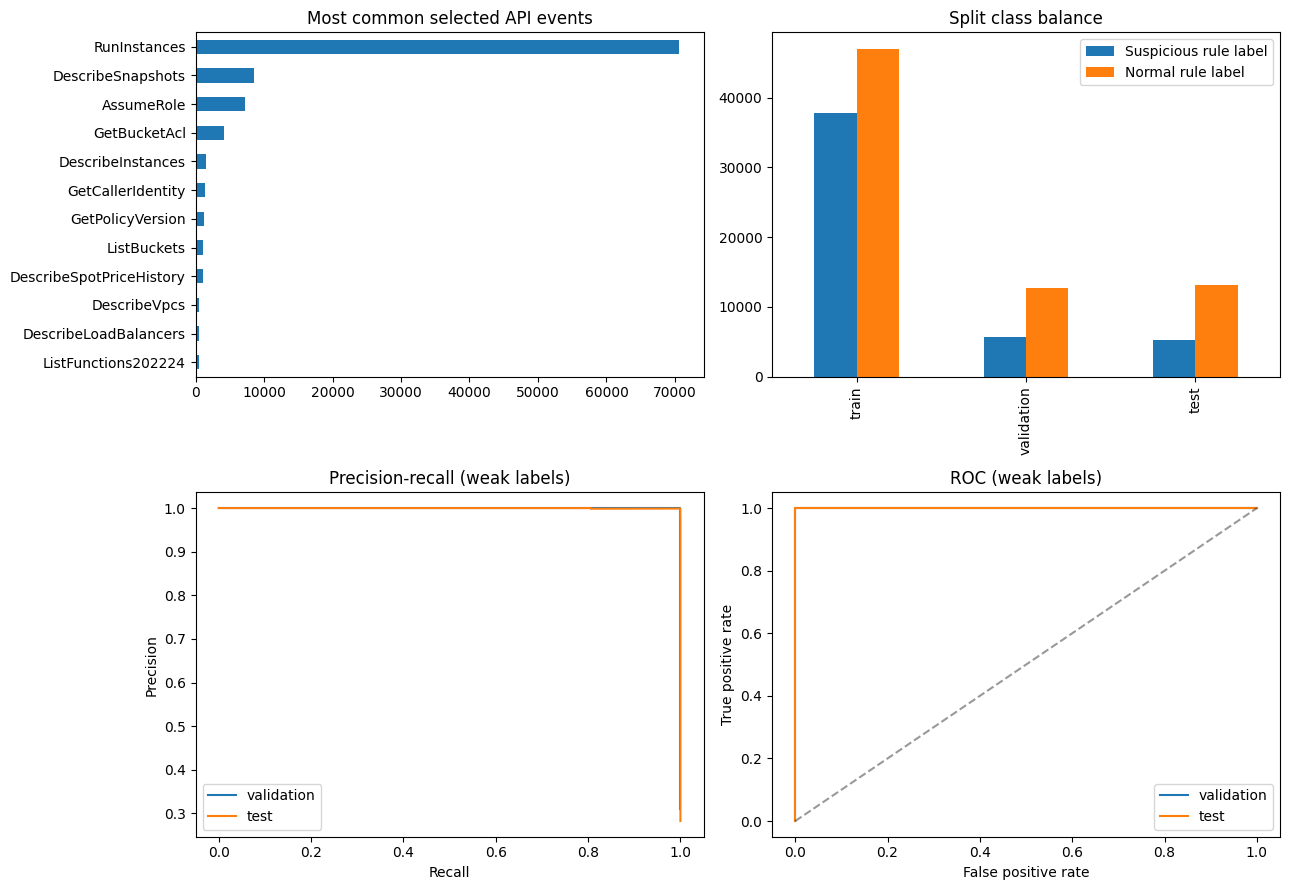

,predicted normal,predicted suspicious
actual normal,13114,51
actual suspicious,1,5183


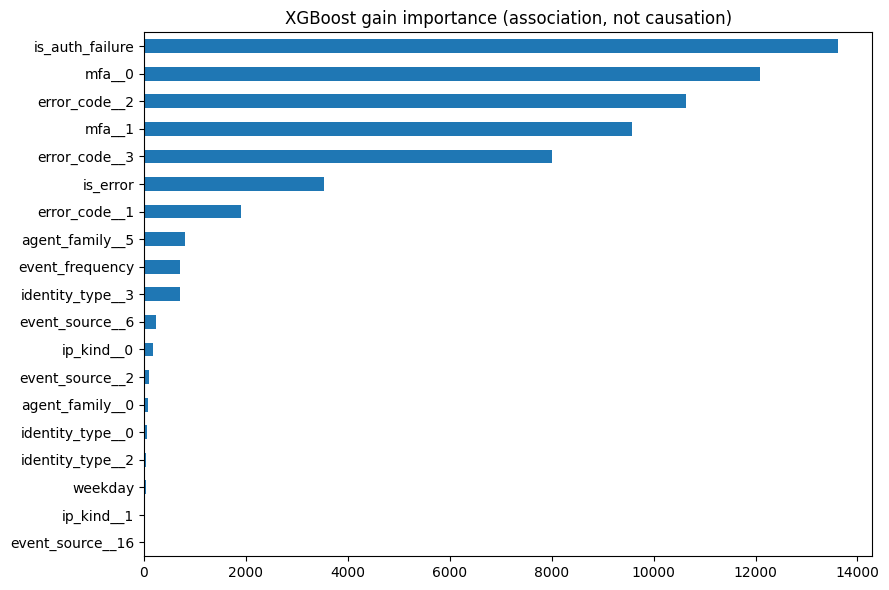

In [34]:
if RUN_PROJECT:
    fig, axes = plt.subplots(2,2,figsize=(13,9))
    pd.Series(dict(profile["top_events_selected"][:12])).sort_values().plot.barh(ax=axes[0,0],title="Most common selected API events")
    pd.DataFrame({s:v["classes"] for s,v in profile["splits"].items()}).T.rename(columns={"0":"Normal rule label","1":"Suspicious rule label"}).plot.bar(ax=axes[0,1],title="Split class balance")
    for split in ("validation","test"):
        c = evaluation[split]["curves"]
        axes[1,0].plot(c["recall"],c["precision"],label=split)
        axes[1,1].plot(c["fpr"],c["tpr"],label=split)
    axes[1,0].set(xlabel="Recall",ylabel="Precision",title="Precision-recall (weak labels)")
    axes[1,1].set(xlabel="False positive rate",ylabel="True positive rate",title="ROC (weak labels)")
    axes[1,1].plot([0,1],[0,1],"k--",alpha=.4)
    for ax in axes[1]: ax.legend()
    plt.tight_layout()
    plt.savefig(REPORTS / "evaluation_plots.png",dpi=160)
    plt.show()
    display(pd.DataFrame(evaluation["test"]["confusion_matrix"],index=["actual normal","actual suspicious"],columns=["predicted normal","predicted suspicious"]))
    pd.Series(evaluation["feature_importance"]).nlargest(20).sort_values().plot.barh(figsize=(9,6),title="XGBoost gain importance (association, not causation)")
    plt.tight_layout(); plt.show()
else:
    print("Evaluation charts will appear after training completes.")


### 7.3 Lineage and release review

- Creates a lineage report linking the model to its data, code, configuration, and evaluation results.
- Records the run ID, source-data location and checksum, library versions, prediction threshold, dataset splits, and quality-gate result.
- Calculates a SHA-256 checksum for each source file so later changes can be detected.
- Saves the report locally as lineage.json and uploads it to S3.
- Updates resources.json with the report’s S3 location and prints that location.
Purpose: Supports traceability, auditing, and reproducibility by documenting how the model was produced.


In [20]:
if RUN_PROJECT:
    import hashlib
    lineage = {
        "run_id": RUN_ID,
        "training_mode": "local_notebook_kernel",
        "raw_uri": raw_uri,
        "archive_sha256": profile["archive_sha256"],
        "xgboost_version": xgb.__version__,
        "sdk_version": SAGEMAKER_SDK_VERSION,
        "threshold": CLASS_THRESHOLD,
        "model_artifact_uri": model_artifact_uri,
        "evaluation_uri": report_uri,
        "quality_gate_passed": quality_gate_passed,
        "splits": profile["splits"],
        "source_hashes": {
            f"{path.parent.name}/{path.name}": hashlib.sha256(path.read_bytes()).hexdigest()
            for path in SRC.glob("*") if path.is_file()
        },
    }
    lineage_path = REPORTS / "lineage.json"
    lineage_path.write_text(json.dumps(lineage, indent=2))
    lineage_uri = f"s3://{BUCKET}/{PREFIX}/reports/lineage.json"
    upload_project_file(lineage_path, f"{PREFIX}/reports/lineage.json")
    resources["lineage_uri"] = lineage_uri
    save_resources()
    print("Lineage report:", lineage_uri)
else:
    print("No lineage report yet.")

Lineage report: s3://sagemaker-us-east-1-939341772580/cloudtrail-risk/20261018-105618/reports/lineage.json


### 7. Upload the Model to AWS SageMaker Regsitry

In [21]:
# Register the trained CloudTrail model in SageMaker Model Registry.
# Compatible with your notebook's SageMaker SDK v2 environment.

from botocore.exceptions import ClientError
from sagemaker.xgboost.model import XGBoostModel
from sagemaker.model_metrics import ModelMetrics, MetricsSource

MODEL_PACKAGE_GROUP = "CloudTrail-Suspicious-Activity-XGBoost"

# Confirm required notebook steps have completed.
required_variables = (
    "model_artifact_uri", "report_uri", "quality_gate_passed",
    "ROLE_ARN", "session", "sm", "SRC", "FRAMEWORK_VERSION",
    "ENDPOINT_INSTANCE", "RUN_ID",
)

missing = [name for name in required_variables if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing notebook variables: {missing}. "
        "Run configuration, preparation, training, and evaluation first."
    )

if not model_artifact_uri or not report_uri:
    raise RuntimeError("Model artifact and evaluation report must exist in S3.")

if not quality_gate_passed:
    raise RuntimeError(
        "Validation quality gate failed. Review the evaluation report."
    )

for filename in ("inference.py", "common.py"):
    if not (SRC / filename).is_file():
        raise FileNotFoundError(f"Required inference source missing: {filename}")

# Create the model group only when it does not already exist.
try:
    sm.describe_model_package_group(
        ModelPackageGroupName=MODEL_PACKAGE_GROUP
    )
    print("Using existing model group:", MODEL_PACKAGE_GROUP)

except ClientError as exc:
    error = exc.response.get("Error", {})
    message = error.get("Message", "").lower()

    if (
        error.get("Code") == "ValidationException"
        and ("does not exist" in message or "could not find" in message)
    ):
        sm.create_model_package_group(
            ModelPackageGroupName=MODEL_PACKAGE_GROUP,
            ModelPackageGroupDescription=(
                "CloudTrail event-level prioritization using XGBoost "
                "trained on rule-generated weak labels."
            ),
        )
        print("Created model group:", MODEL_PACKAGE_GROUP)
    else:
        raise

# Preserve custom preprocessing and inference behavior.
# The SDK packages source code with the model for registration.
registry_model = XGBoostModel(
    model_data=model_artifact_uri,
    entry_point="inference.py",
    source_dir=str(SRC),
    framework_version=FRAMEWORK_VERSION,
    py_version="py3",
    role=ROLE_ARN,
    sagemaker_session=session,
)

model_metrics = ModelMetrics(
    model_statistics=MetricsSource(
        s3_uri=report_uri,
        content_type="application/json",
    )
)

registered_model = registry_model.register(
    model_package_group_name=MODEL_PACKAGE_GROUP,
    content_types=["application/json"],
    response_types=["application/json"],
    inference_instances=[ENDPOINT_INSTANCE],
    transform_instances=[ENDPOINT_INSTANCE],
    model_metrics=model_metrics,
    approval_status="PendingManualApproval",
    description=(
        f"CloudTrail XGBoost run {RUN_ID}. "
        "Trained in notebook kernel. Validation gate passed. "
        "Evaluation measures agreement with weak rules, "
        "not independently verified attacks."
    ),
    customer_metadata_properties={
        "run_id": str(RUN_ID),
        "label_source": "weak_rules",
        "training_mode": "local_notebook_kernel",
        "validation_gate": "passed",
    },
)

model_package_arn = registered_model.model_package_arn

# Persist the registry reference alongside existing project resources.
resources["model_package_group"] = MODEL_PACKAGE_GROUP
resources["model_package_arn"] = model_package_arn
save_resources()

details = sm.describe_model_package(
    ModelPackageName=model_package_arn
)

print("Model package ARN:", model_package_arn)
print("Version:", details["ModelPackageVersion"])
print("Registration status:", details["ModelPackageStatus"])
print("Approval status:", details["ModelApprovalStatus"])

/home/sagemaker-user/.venvs/cloudtrail-sagemaker-v2/lib/python3.12/site-packages/sagemaker/model.py:347: SageMakerV2DeprecationWarning: XGBoostModel is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
XGBoostModel is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


Using existing model group: CloudTrail-Suspicious-Activity-XGBoost


/home/sagemaker-user/.venvs/cloudtrail-sagemaker-v2/lib/python3.12/site-packages/sagemaker/model.py:347: SageMakerV2DeprecationWarning: ModelPackage is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
ModelPackage is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


Model package ARN: arn:aws:sagemaker:us-east-1:939341772580:model-package/CloudTrail-Suspicious-Activity-XGBoost/4
Version: 4
Registration status: Completed
Approval status: PendingManualApproval


### 7.1 Model Version Approval
![Approval](resources/Approval.png)

#### 7.2 Model Approved
![Approved](resources/Approved.png)


## 8. Deploy a real-time endpoint

- Review the validation and test reports, weak-label limitations, and validation gate before deployment.
- Set `APPROVE_MODEL=True` only after that review, then set `DEPLOY_ENDPOINT=True` and run the deployment cell.
- The endpoint accepts **normalized features**, not arbitrary raw CloudTrail JSON.
- Use the shared `normalize()` function and the exact serving field list shown below. It returns a risk score, target class, threshold, and label source.
- Data capture is enabled for later monitoring; captured inputs exclude raw IPs, principals, request/response payloads, and event IDs (inference IDs remain correlation metadata).
- Configures the trained XGBoost model with its custom inference.py code.
- Enables capture of 100% of prediction requests and responses to S3 for later analysis and monitoring.
Saves the endpoint name in the resource-tracking file.
- Deploys the model on one separate SageMaker hosting instance of type ENDPOINT_INSTANCE.
Configures JSON input and output, then prints the endpoint name when ready.

In [24]:
predictor = None
if DEPLOY_ENDPOINT:
    from sagemaker.xgboost.model import XGBoostModel
    from sagemaker.predictor import Predictor
    from sagemaker.serializers import JSONSerializer
    from sagemaker.deserializers import JSONDeserializer
    from sagemaker.model_monitor import DataCaptureConfig

    if not RUN_PROJECT or not model_artifact_uri:
        raise RuntimeError("Run notebook-kernel training and upload the model artifact before deploying.")
    if not quality_gate_passed:
        raise RuntimeError("Validation F1/recall gate did not pass; review the reports before deployment.")
    if not APPROVE_MODEL:
        raise RuntimeError("Review validation/test reports, then set APPROVE_MODEL=True to deploy.")

    model = XGBoostModel(
        model_data=model_artifact_uri, entry_point="inference.py", source_dir=str(SRC),
        framework_version=FRAMEWORK_VERSION, py_version="py3", role=ROLE_ARN,
        sagemaker_session=session, predictor_cls=Predictor,
    )
    capture = DataCaptureConfig(enable_capture=True, sampling_percentage=100,
        destination_s3_uri=f"s3://{BUCKET}/{PREFIX}/capture", kms_key_id=KMS_KEY_ID,
        capture_options=["Input","Output"], json_content_types=["application/json"])
    resources["endpoint_name"] = ENDPOINT_NAME
    save_resources()
    predictor = model.deploy(initial_instance_count=1, instance_type=ENDPOINT_INSTANCE,
        endpoint_name=ENDPOINT_NAME, data_capture_config=capture)
    predictor.serializer = JSONSerializer()
    predictor.deserializer = JSONDeserializer()
    print("Endpoint is ready:", ENDPOINT_NAME)
else:
    print("Deployment skipped. Review reports before enabling APPROVE_MODEL and DEPLOY_ENDPOINT.")

--------!

/home/sagemaker-user/.venvs/cloudtrail-sagemaker-v2/lib/python3.12/site-packages/sagemaker/base_predictor.py:140: SageMakerV2DeprecationWarning: Predictor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.resources.Endpoint`.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
Predictor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.resources.Endpoint`.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


Endpoint is ready: cloudtrail-risk-20261018-105618


![Endpoint](resources/Endpoint.png)

## 9. Run Predictions on the SageMaker Endpoint

We send two event to the SageMaker Endpoint 

In [27]:
import sys
import uuid
import pandas as pd
from IPython.display import display, Markdown

sys.path.insert(0, str(SRC.resolve()))
from common import normalize, weak_label, CATS, NUMS

# Two synthetic test events.
events = {
    "IAM — Create Access Key": {
        "eventTime": "2024-01-01T12:00:00Z",
        "eventSource": "iam.amazonaws.com",
        "eventName": "CreateAccessKey",
        "awsRegion": REGION,
        "sourceIPAddress": "192.0.2.10",
        "userAgent": "aws-cli/2",
        "userIdentity": {
            "type": "IAMUser",
            "sessionContext": {
                "attributes": {"mfaAuthenticated": "false"}
            },
        },
    },
    "Root — Stop CloudTrail Logging": {
        "eventTime": "2024-01-01T02:30:00Z",
        "eventSource": "cloudtrail.amazonaws.com",
        "eventName": "StopLogging",
        "awsRegion": REGION,
        "sourceIPAddress": "192.0.2.10",
        "userAgent": "aws-cli/2",
        "readOnly": False,
        "userIdentity": {
            "type": "Root",
            "sessionContext": {
                "attributes": {"mfaAuthenticated": "false"}
            },
        },
    },
}


def predict_event(name, event):
    """Score one event and compare the prediction with its weak label."""
    row = normalize(event)
    record = {key: row[key] for key in CATS + NUMS + ["ip_hash"]}
    expected_label, reasons = weak_label(row)

    response = predictor.predict(
        {"instances": [record]},
        initial_args={"InferenceId": "synthetic-" + uuid.uuid4().hex},
    )

    result = response["predictions"][0]
    score = float(result["risk_score"])
    threshold = float(result["threshold"])
    predicted_label = int(result["CloudTrail_Activity_Risk"])

    assert 0 <= score <= 1, "Risk score is outside the expected range."
    assert predicted_label == int(score >= threshold), (
        "Prediction does not match the endpoint threshold."
    )

    return {
        "Event": name,
        "Identity": row["identity_type"],
        "Risk Score": score,
        "Threshold": threshold,
        "Model Prediction": "Suspicious" if predicted_label else "Normal",
        "Rule Label": "Suspicious" if expected_label else "Normal",
        "Agreement": "Match" if predicted_label == expected_label else "Mismatch",
        "Rule Reasons": ", ".join(
            reason.replace("_", " ") for reason in reasons
        ) or "None",
    }


def highlight_result(value):
    if value in ("Suspicious", "Mismatch"):
        return "background-color: #fff0f0; color: #9c2020;"
    if value == "Match":
        return "background-color: #eaf6ed; color: #236535;"
    return ""


if predictor is None:
    print("Deploy the endpoint before running these tests.")
else:
    # Separate endpoint invocation for each event.
    results = [
        predict_event(name, event)
        for name, event in events.items()
    ]

    results_df = pd.DataFrame(results)

    display(Markdown("## Synthetic Event Predictions"))

    display(
        results_df.style
        .hide(axis="index")
        .format({"Risk Score": "{:.4f}", "Threshold": "{:.2f}"})
        .map(
            highlight_result,
            subset=["Model Prediction", "Agreement"],
        )
        .set_properties(**{
            "text-align": "left",
            "white-space": "normal",
        })
        .set_caption("Endpoint predictions compared with security-rule labels")
    )

    matches = int((results_df["Agreement"] == "Match").sum())

## Synthetic Event Predictions

Event,Identity,Risk Score,Threshold,Model Prediction,Rule Label,Agreement,Rule Reasons
IAM — Create Access Key,IAMUser,0.2208,0.50,Normal,Suspicious,Mismatch,iam sensitive change
Root — Stop CloudTrail Logging,Root,0.6429,0.50,Suspicious,Suspicious,Match,"root activity, trail change"


The model identified the root logging-change scenario but missed the IAM access-key scenario. This demonstrates that high overall evaluation scores do not guarantee agreement on every security-sensitive event.
These two tests verify endpoint behavior; they are too few to establish detection performance.

## 9. Observability 
- Measure latency, memory, request rate, and tail latency before production sizing or autoscaling.
- Real-time serving supports event-by-event triage; batch scoring is more cost-effective for purely retrospective investigations.
- Endpoint behavior and production controls
- For rollback, preserve the previous approved model package and endpoint configuration.
  
**Endpoint health — CloudWatch alarms**

- Creates alarms for:- **Server errors**: more than 5 invocation **5xx errors per five-minute** period.
- Latency: average **model latency above 1 second per five-minute** period.
- Requires the threshold to be exceeded for two consecutive periods.
- Sends notifications if SNS_TOPIC_ARN is configured.
- Saves alarm names for later cleanup.

In [32]:
ENABLE_MONITORING = True
if ENABLE_MONITORING:
    if not resources.get("endpoint_name"):
        raise ValueError("Deploy an endpoint before creating monitors.")
    dims = [{"Name":"EndpointName","Value":ENDPOINT_NAME},{"Name":"VariantName","Value":"AllTraffic"}]
    alarm_names = []
    for suffix,metric,stat,threshold in [("5xx","Invocation5XXErrors","Sum",5),
                                          ("latency","ModelLatency","Average",1_000_000)]:
        name = f"{ENDPOINT_NAME}-{suffix}"
        cw.put_metric_alarm(AlarmName=name,Namespace="AWS/SageMaker",MetricName=metric,
            Dimensions=dims,Statistic=stat,Period=300,EvaluationPeriods=2,Threshold=threshold,
            ComparisonOperator="GreaterThanThreshold",TreatMissingData="notBreaching",
            AlarmActions=[SNS_TOPIC_ARN] if SNS_TOPIC_ARN else [])
        alarm_names.append(name)
    resources["alarm_names"] = alarm_names
    save_resources()
    print("Infrastructure alarms created; latency is in microseconds.")
else:
    print("Monitoring skipped until ENABLE_MONITORING is enabled.")


Infrastructure alarms created; latency is in microseconds.


![Alarms](resources/alarms.png)

#### Data quality
- Builds reference statistics and constraints from the training baseline.
- Upload the preprocessing script used to interpret captured requests.
- Schedules hourly checks comparing endpoint input data against the baseline.
- Stores monitoring reports in S3 and publishes CloudWatch metrics.
- Uses separate Processing compute, which can incur charges.
- Checks input data quality and drift; it does not measure prediction accuracy without ground-truth labels.

In [39]:
ENABLE_MONITORING = False   
## LabRole/SageMaker is not authorized to perform: sagemaker:CreateProcessingJob on resource: 
if ENABLE_MONITORING:
    from sagemaker.model_monitor import DefaultModelMonitor, DatasetFormat, CronExpressionGenerator
    baseline_uri = monitor_baseline_uri or resources.get("monitor_baseline_uri")
    if not baseline_uri:
        raise ValueError("Training baseline is unavailable. Run the direct preparation/training steps first.")
    monitor = DefaultModelMonitor(role=ROLE_ARN,instance_count=1,instance_type=PROCESSING_INSTANCE,
        volume_size_in_gb=30,max_runtime_in_seconds=1800,sagemaker_session=session)
    monitor.suggest_baseline(baseline_dataset=baseline_uri,
        dataset_format=DatasetFormat.csv(header=True),
        output_s3_uri=f"s3://{BUCKET}/{PREFIX}/monitoring/baseline",wait=True,logs=True)
    baseline_job = monitor.latest_baselining_job
    monitor_script_uri = session.upload_data(str(SRC/"monitor_preprocess.py"),bucket=BUCKET,key_prefix=f"{PREFIX}/monitoring/code")
    schedule_name = f"cloudtrail-data-{RUN_ID}"
    monitor.create_monitoring_schedule(monitor_schedule_name=schedule_name,endpoint_input=ENDPOINT_NAME,
        output_s3_uri=f"s3://{BUCKET}/{PREFIX}/monitoring/reports",
        statistics=baseline_job.baseline_statistics(),constraints=baseline_job.suggested_constraints(),
        record_preprocessor_script=monitor_script_uri,
        schedule_cron_expression=CronExpressionGenerator.hourly(),enable_cloudwatch_metrics=True)
    resources["monitor_schedule"] = schedule_name
    description = sm.describe_monitoring_schedule(MonitoringScheduleName=schedule_name)
    resources["data_quality_job_definition"] = description["MonitoringScheduleConfig"].get("MonitoringJobDefinitionName")
    save_resources()
    print("Hourly data-quality schedule:",schedule_name)


- Monitoring results take time to appear after captured traffic is uploaded to S3 and the scheduled job completes. - Model Monitor emits execution metrics; inspect the actual metric names/dimensions in CloudWatch before creating feature-violation alarms for the selected container.

In [40]:
if resources.get("monitor_schedule"):
    result = sm.list_monitoring_executions(MonitoringScheduleName=resources["monitor_schedule"],MaxResults=10)
    display(pd.DataFrame(result.get("MonitoringExecutionSummaries",[])))
else:
    print("No data-quality schedule created.")


No data-quality schedule created.


## 10. Future Enhancements

The following improvements would strengthen detection quality, scalability, and operational readiness. These are proposed enhancements, not currently implemented capabilities.

| Enhancement | Planned Improvement | Expected Benefit |
|:---|:---|:---|
| **Independent security labels** | Have analysts review a time-separated dataset and label suspicious and legitimate activity. | Measure detection effectiveness beyond agreement with existing rules. |
| **Rules-plus-model detection** | Combine mandatory security rules with model-based prioritization. Investigate missed scenarios such as `CreateAccessKey`. | Improve policy coverage while keeping rule alerts and model scores distinguishable. |
| **Activity across sessions** | Add historical features for repeated authorization failures, API bursts, and unusual IP or region usage. Use only information available before each prediction. | Detect patterns that individual-event scoring cannot capture. |
| **Threshold tuning and calibration** | Select thresholds using validation data, analyst capacity, and false-alert costs. Assess calibration against independently reviewed labels. | Balance missed events and investigation workload. |
| **Broader validation** | Test on newer logs, unseen accounts and identities, and a wider range of legitimate and suspicious scenarios. | Assess how well the system generalizes beyond the historical dataset. |
| **Automated ML lifecycle** | Add version-controlled CI/CD, reproducible training jobs, registry approval, deployment tests, and rollback. | Make updates more repeatable and reduce manual errors. |
| **Operational monitoring** | Track data drift, endpoint health, alert volume, analyst feedback, and detection quality when reviewed labels become available. | Identify failures and degradation; trigger investigation before retraining. |
| **Security and cost controls** | Strengthen private-network access, dependency scanning, retention policies, alert deduplication, and workload-based capacity planning. | Protect sensitive logs and control operating costs. |

**Priority:** First investigate missed security scenarios and establish independent evaluation labels. Then add historical activity features and automate the deployment lifecycle.





## 11. AWS resources cleanup

Set `CLEAN_UP = True` only after reviewing the run's endpoint, monitoring schedule, and alarms. The cleanup cell removes the endpoint and run-specific monitoring resources recorded for this notebook. It preserves S3 data, model artifacts, shared SNS topics, IAM roles, and CloudWatch logs. The locally fitted model artifact remains in S3 and can incur storage charges.

In [31]:
CLEAN_UP = False
if CLEAN_UP and RUN_PROJECT:
    resources = json.loads((PROJECT/"resources.json").read_text())
    def if_exists(fn, **kwargs):
        try: return fn(**kwargs)
        except ClientError as e:
            err = e.response["Error"]
            msg = err.get("Message", "").lower()
            if err["Code"] in ("ResourceNotFoundException","ResourceNotFound") or (err["Code"]=="ValidationException" and any(t in msg for t in ("does not exist","could not find","not found"))):
                return None
            raise
    schedule = resources.get("monitor_schedule")
    if schedule:
        desc = if_exists(sm.describe_monitoring_schedule,MonitoringScheduleName=schedule)
        if desc:
            if_exists(sm.stop_monitoring_schedule,MonitoringScheduleName=schedule)
            # Avoid deleting a schedule with an in-progress monitoring execution.
            runs = sm.list_monitoring_executions(MonitoringScheduleName=schedule).get("MonitoringExecutionSummaries",[])
            if any(r["MonitoringExecutionStatus"] in ("Pending","InProgress") for r in runs):
                raise RuntimeError("Monitoring execution is active. Wait for completion, then rerun cleanup.")
            if_exists(sm.delete_monitoring_schedule,MonitoringScheduleName=schedule)
            for _ in range(60):
                if if_exists(sm.describe_monitoring_schedule,MonitoringScheduleName=schedule) is None: break
                time.sleep(5)
            else: raise RuntimeError("Schedule deletion is pending. Rerun cleanup shortly.")
        if resources.get("data_quality_job_definition"):
            if_exists(sm.delete_data_quality_job_definition,JobDefinitionName=resources["data_quality_job_definition"])
    endpoint = resources.get("endpoint_name")
    if endpoint:
        description = if_exists(sm.describe_endpoint,EndpointName=endpoint)
        if description:
            config_name = description["EndpointConfigName"]
            config = sm.describe_endpoint_config(EndpointConfigName=config_name)
            # Persist before deleting so a retry can finish cleanup after interruption.
            resources["endpoint_config"] = config_name
            resources["model_names"] = [v["ModelName"] for v in config["ProductionVariants"]]
            (PROJECT/"resources.json").write_text(json.dumps(resources,indent=2))
            sm.delete_endpoint(EndpointName=endpoint)
            sm.get_waiter("endpoint_deleted").wait(EndpointName=endpoint)
        if resources.get("endpoint_config"):
            if_exists(sm.delete_endpoint_config,EndpointConfigName=resources["endpoint_config"])
        for name in resources.get("model_names",[]):
            if_exists(sm.delete_model,ModelName=name)
    if resources.get("alarm_names"):
        cw.delete_alarms(AlarmNames=resources["alarm_names"])
    print("Run-specific live resources removed. Review retained S3 artifacts and logs separately.")
else:
    print("Cleanup skipped. Active endpoints and monitoring schedules can continue to incur charges.")


Cleanup skipped. Active endpoints and monitoring schedules can continue to incur charges.
